# Season features and the log target, revisited (Oct 9, 2026)

**#1 Season features.** Every remaining error traced back to one blind spot: the look-direction features `n·*` don't
know *where Earth is in its orbit* (the late-test drift, extra scatter within ~2° of the ecliptic poles, ~16% too-weak
north/south asymmetry from the tilted cloud). Here the model gets Earth's orbital phase explicitly: `sin λ⊕`, `cos λ⊕`
(λ⊕ = Earth's ecliptic longitude; periodic over a year).

*Physics caveat, decided in advance:* the mission covers only 134° of Earth's orbit (λ⊕ = 214.5° → 348.3°), so on a
**chronological** split the season features are out of their training range (84–100% of test rows) — exactly like the
earlier "clock" features. Their real test is **interpolation** (30-day blocks, random split), which is what a full year
of real data will look like. Primary verdict: interpolation; chronological shown for honesty.

**#3 Log target revisited.** On 10/07 the log target (predict log y) won validation and all-sky fractional error but was
seed-sensitive. Here: 10 seeds each of linear and log target (paired by seed), plus a **mixed loss**
`MSE(y) + α·MSE(log y)` (network predicts log y, so outputs are always positive) with α = 0.25 (≈ equal weight at y ≈ 0.5)
and α = 1 (log-leaning).

All runs: 64-64-32-16 MLP, one-cycle LR (peak 1e-3), 100 epochs (`sweeps/configs_v7.jl`). This notebook loads the saved
results and runs top-to-bottom in a few minutes.

### Summary
| question | result |
|---|---|
| **#1 Do season features help where the season is covered (interpolation)?** | **Yes — 44–65× lower test MSE.** 30-day blocks: ensemble 8.8e-6 → **2.0e-7** (median error 0.14% → **0.032%**); random: 1.0e-5 → **1.6e-7** (0.11% → **0.026%**). Leakage checks pass. |
| …and do the physical symptoms go away? | **Yes.** Error within 2° of the poles: rms 2.5–4.4% → **0.03–0.04%**; north/south asymmetry pattern correlation 0.58 → **0.998**, amplitude 73% → **98%** of Kelsall's; the model now tracks the seasonal pole brightness. |
| …and when extrapolating (chronological)? | Still better, despite season features being out of range: validation 3.1e-5 → 3.5e-7, test 2.7e-4 → **3.8e-5** (7×), late drift −0.014 → +0.003. |
| **#3 Is the log target better with 10 seeds?** | **No (chronological).** It beats linear in only 2 of 10 paired seeds (median MSE 2.4× worse); the mixed loss lands in between. It does give the best all-sky in-domain fractional error (0.32% vs 0.59%), but an exp output can blow up toward the Sun (mixed α=0.25: median 1100% near the Sun). **Linear output stays.** |

**Bottom line:** Earth's orbital phase was the missing variable. With it the emulator interpolates at ~0.03% —
about 20× below the 0.5–0.6% of the current model — and the remaining residuals sit at the ecliptic (dust bands).


In [1]:
include(joinpath(@__DIR__, "..", "zodi_setup.jl"))
for f in ("mb_train.jl", "extra_features.jl", "nb_verify_fns.jl", "summary_helpers.jl", "checks_helpers.jl", "season_helpers.jl")
    include(joinpath(@__DIR__, "..", "sweeps", f))
end


  Activating project at `c:\JuliaProjects\More_zodi`


description: Zodiacal light predictions for SPHEREx pointing directions
wavelength:  5.0 micron
units:       MJy/sr
N = 423607 exposures;  emission range = (0.31956938511238003, 1.0941130974339088)
n·n     median  1.000e+00   iqr  0.000e+00
n·S     median  4.851e-03   iqr  3.475e-01
n·z     median  9.747e-03   iqr  1.361e+00
n·E     median  4.805e-03   iqr  3.475e-01
n·vS    median  1.615e-02   iqr  1.356e+00
n·vE    median  3.680e-02   iqr  1.383e+00
n·J     median -5.953e-02   iqr  2.659e+00
n·x     median  5.145e-02   iqr  8.549e-01
n·y     median -1.072e-03   iqr  5.523e-01
S·S     median  1.037e+00   iqr  1.341e-02
S·z     median  2.050e-04   iqr  6.195e-05
S·E     median  1.037e+00   iqr  1.341e-02
S·vS    median -1.048e-02   iqr  5.980e-02
S·vE    median -5.250e-03   iqr  2.289e-02
S·J     median -4.519e+00   iqr  1.400e+00
S·x     median  2.056e-01   iqr  1.095e+00
S·y     median -8.518e-01   iqr  3.210e-01
z·z     median  1.000e+00   iqr  0.000e+00
z·E     median  2.096e-04   

## #1 Season features

### 1a. Pre-flight: are the season features physically right, and where are they in range?


In [2]:
o = sortperm(t_rel)
@printf("Earth's ecliptic longitude: day 0 → %.1f°, day 139.7 → %.1f° (%.1f° of the orbit)\n",
        λE_deg[o[1]], λE_deg[o[end]], mod(λE_deg[o[end]] - λE_deg[o[1]], 360))
sunλ = mod.(atand.(-spherex_positions[2, :], -spherex_positions[1, :]), 360)
@printf("consistency: λ⊕ − (Sun's longitude seen from SPHEREx) = 180° to within %.2f° (median)\n", median(abs.(mod.(λE_deg .- sunλ, 360) .- 180)))
s_, c_ = Fd_raw[:, findfirst(==("sinλE"), dot_names_all)], Fd_raw[:, findfirst(==("cosλE"), dot_names_all)]
for sp in ("random split", "30 day split", "80/20 Chronological")
    tr, te = splits[sp]; sp == "80/20 Chronological" && (tr = tr[t_rel[tr] .< 100])
    frac(v) = begin lo, hi = extrema(v[tr]); 100mean((v[te] .< lo) .| (v[te] .> hi)) end
    @printf("%-20s test rows outside the training range: sin λ⊕ %5.1f%%   cos λ⊕ %5.1f%%\n", sp, frac(s_), frac(c_))
end
println("(30-day blocks: sin λ⊕ reaches its minimum at λ⊕ = 270°, which falls inside a test block → 6.8% slightly out of range)")


Earth's ecliptic longitude: day 0 → 214.5°, day 139.7 → 348.3° (133.8° of the orbit)
consistency: λ⊕ − (Sun's longitude seen from SPHEREx) = 180° to within 0.00° (median)
random split         test rows outside the training range: sin λ⊕   0.0%   cos λ⊕   0.0%
30 day split         test rows outside the training range: sin λ⊕   6.8%   cos λ⊕   0.0%
80/20 Chronological  test rows outside the training range: sin λ⊕  83.9%   cos λ⊕ 100.0%
(30-day blocks: sin λ⊕ reaches its minimum at λ⊕ = 270°, which falls inside a test block → 6.8% slightly out of range)


### 1b. Accuracy — interpolation (primary) and chronological


In [3]:
println("30-day alternating blocks:"); display(compare_table(S_BLOCK))
println("random 50/50 (seeds 42–44):"); display(compare_table(S_RANDOM))
println("chronological, fit days 0–100 (season features extrapolate here):"); display(compare_table(S_CHRONO))


Row,variant,seeds,val_ens,test_seed_median,test_seed_range,test_ens,test_ens_median_frac_pct,late_test_bias
,String,Int64,String,String,String,String,Float64,String
1,baseline n·*,5,—,1.27e-05,1.03e-05 – 1.57e-05,8.82e-06,0.142,—
2,n·* + sin/cos λ⊕,5,—,4.23e-07,2.71e-07 – 5.04e-07,2.02e-07,0.032,—


30-day alternating blocks:
random 50/50 (seeds 42–44):
chronological, fit days 0–100 (season features extrapolate here):


Row,variant,seeds,val_ens,test_seed_median,test_seed_range,test_ens,test_ens_median_frac_pct,late_test_bias
,String,Int64,String,String,String,String,Float64,String
1,baseline n·*,3,—,1.17e-05,1.05e-05 – 1.28e-05,1.03e-05,0.114,—
2,n·* + sin/cos λ⊕,3,—,1.84e-07,1.61e-07 – 2.83e-07,1.58e-07,0.026,—


Row,variant,seeds,val_ens,test_seed_median,test_seed_range,test_ens,test_ens_median_frac_pct,late_test_bias
,String,Int64,String,String,String,String,Float64,String
1,baseline n·*,5,3.09e-05,4.46e-04,3.28e-04 – 5.59e-04,2.67e-04,1.438,-0.0144
2,n·* + sin/cos λ⊕,5,3.53e-07,1.45e-04,8.18e-05 – 2.29e-04,3.75e-05,0.283,+0.0033


### 1b′. Is a 30–60× improvement real? Leakage checks
A gain this large deserves scrutiny. (1) Splits are clean partitions with training-only normalization. (2) Test exposures
are far from training ones in time on the block split, yet the gain matches the random split's → it is not "near-duplicate
neighbours" leaking. (3) `sin/cos λ⊕` is a function of time only — Earth's orbital position, which is exactly the observer
information Kelsall depends on (the line of sight starts at the observer) and which the `n·*` set lacked; it contains no
information about the target itself.


In [4]:
for (lbl, spec) in (S_BLOCK[2], S_RANDOM[2])
    rs = grp_runs(spec); r = rs[1]; tr, te = r.tr_idx, r.te_idx
    cols = [findfirst(==(nm), dot_names_all) for nm in r.feature_names]
    ok_part = isempty(intersect(tr, te)) && sort(vcat(tr, te)) == collect(1:N)
    ok_norm = all(r.μ ≈ [median(Fd_raw[tr, c]) for c in cols] for r in rs)
    gaps = gap_days(tr, te)
    @printf("%-28s %-14s partition ok: %s | normalization from training rows: %s | test→nearest training exposure: median %.2f d, max %.1f d\n",
            lbl, r.split_name, ok_part, ok_norm, median(gaps), maximum(gaps))
end
rs = grp_runs(S_BLOCK[2][2])
println("\npermutation importance on the 30-day-block TEST blocks (season model ensemble):")
perm_importance(rs, rs[1].te_idx)


n·* + sin/cos λ⊕             30 day split   partition ok: true | normalization from training rows: true | test→nearest training exposure: median 7.41 d, max 15.0 d
n·* + sin/cos λ⊕             random split   partition ok: true | normalization from training rows: true | test→nearest training exposure: median 0.00 d, max 0.0 d

permutation importance on the 30-day-block TEST blocks (season model ensemble):


Row,feature,mse_ratio_when_shuffled
,String,Float64
1,n·z,83047.3
2,n·S,41482.8
3,n·E,24462.7
4,n·vE,21837.7
5,n·x,19797.9
6,n·J,7846.79
7,n·y,4223.49
8,cosλE,3844.91
9,n·vS,652.15


### 1c. Does knowing the season fix the physical symptoms?
**(i) Scatter near the ecliptic poles** — on the test blocks of the interpolation split:


In [5]:
pole_table(S_BLOCK)


Row,model,pole,n,median_pct,p05_pct,p95_pct,rms_pct
,String,String,Int64,Float64,Float64,Float64,Float64
1,baseline n·*,north 0–2°,4263,2.161,-0.13,4.24,2.501
2,baseline n·*,north 2–10°,15926,0.321,-1.59,3.06,1.444
3,baseline n·*,south 0–2°,428,2.089,-5.23,7.48,4.369
4,baseline n·*,south 2–10°,18587,0.14,-0.82,0.58,0.635
5,n·* + sin/cos λ⊕,north 0–2°,4263,0.014,-0.01,0.09,0.038
6,n·* + sin/cos λ⊕,north 2–10°,15926,0.009,-0.02,0.08,0.038
7,n·* + sin/cos λ⊕,south 0–2°,428,0.015,-0.02,0.06,0.026
8,n·* + sin/cos λ⊕,south 2–10°,18587,-0.002,-0.04,0.06,0.027


**(ii) The pole brightness through the mission** — the Kelsall pole brightness changes with the season (Earth's position
relative to the ~2°-tilted cloud). Without season information the network cannot follow it.


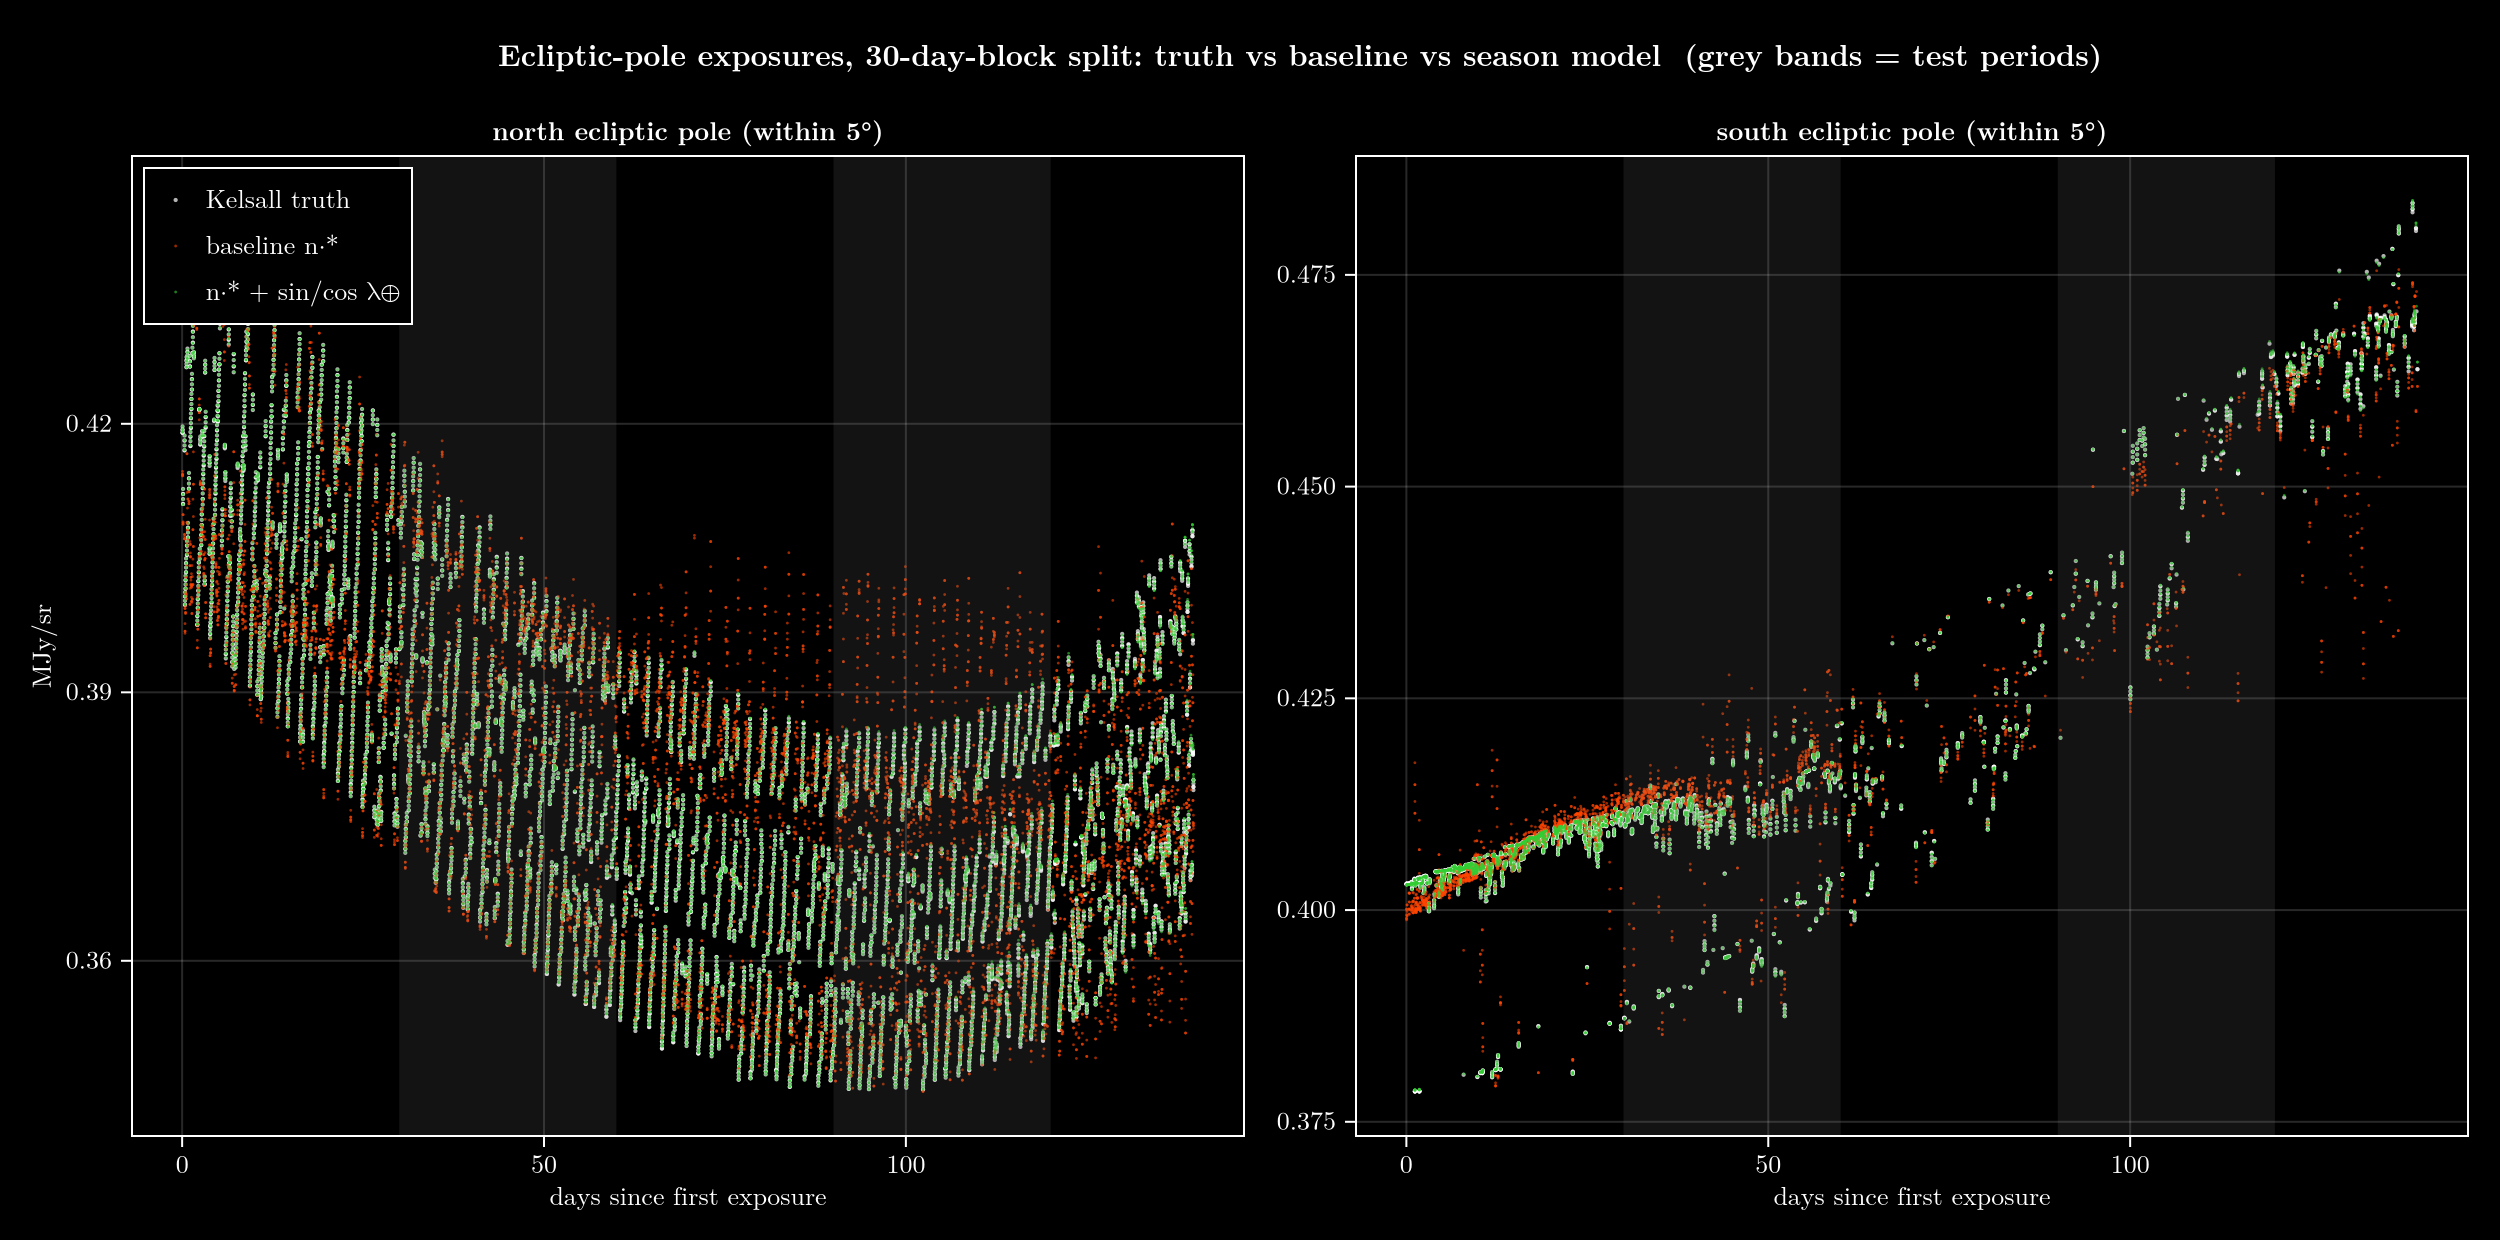

In [6]:
pole_series_fig(S_BLOCK; title="Ecliptic-pole exposures, 30-day-block split: truth vs baseline vs season model")


**(iii) North/south asymmetry of the tilted cloud on the all-sky map** (epoch 13170 = day 0, a training day for the block
split). Before: the model reproduced only ~84% of the amplitude.


In [7]:
asym_rows = map(S_BLOCK) do (lbl, spec)
    A = allsky_eval(grp_runs(spec); title=lbl); a = ns_asymmetry(A)
    (; model=lbl, in_domain_pct=round(A.metrics.sky_pct[1], digits=1), in_domain_median_err_pct=round(A.metrics.median_abs_frac_pct[1], digits=3),
       north_minus_south_model_pct=round(a.model_mean_pct, digits=2), truth_pct=round(a.truth_mean_pct, digits=2),
       pattern_corr=round(a.pattern_corr, digits=3), amplitude_ratio=round(a.amplitude_ratio, digits=3),
       above_60deg_model_pct=round(a.highlat_model_pct, digits=2), above_60deg_truth_pct=round(a.highlat_truth_pct, digits=2))
end
DataFrame(asym_rows)


Row,model,in_domain_pct,in_domain_median_err_pct,north_minus_south_model_pct,truth_pct,pattern_corr,amplitude_ratio,above_60deg_model_pct,above_60deg_truth_pct
,String,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64
1,baseline n·*,35.1,0.693,5.82,8.73,0.581,0.73,10.55,10.84
2,n·* + sin/cos λ⊕,35.1,0.166,8.55,8.73,0.998,0.984,10.69,10.84


**(iv) Residuals vs time, latitude and elongation** (5-seed ensembles, interpolation split):


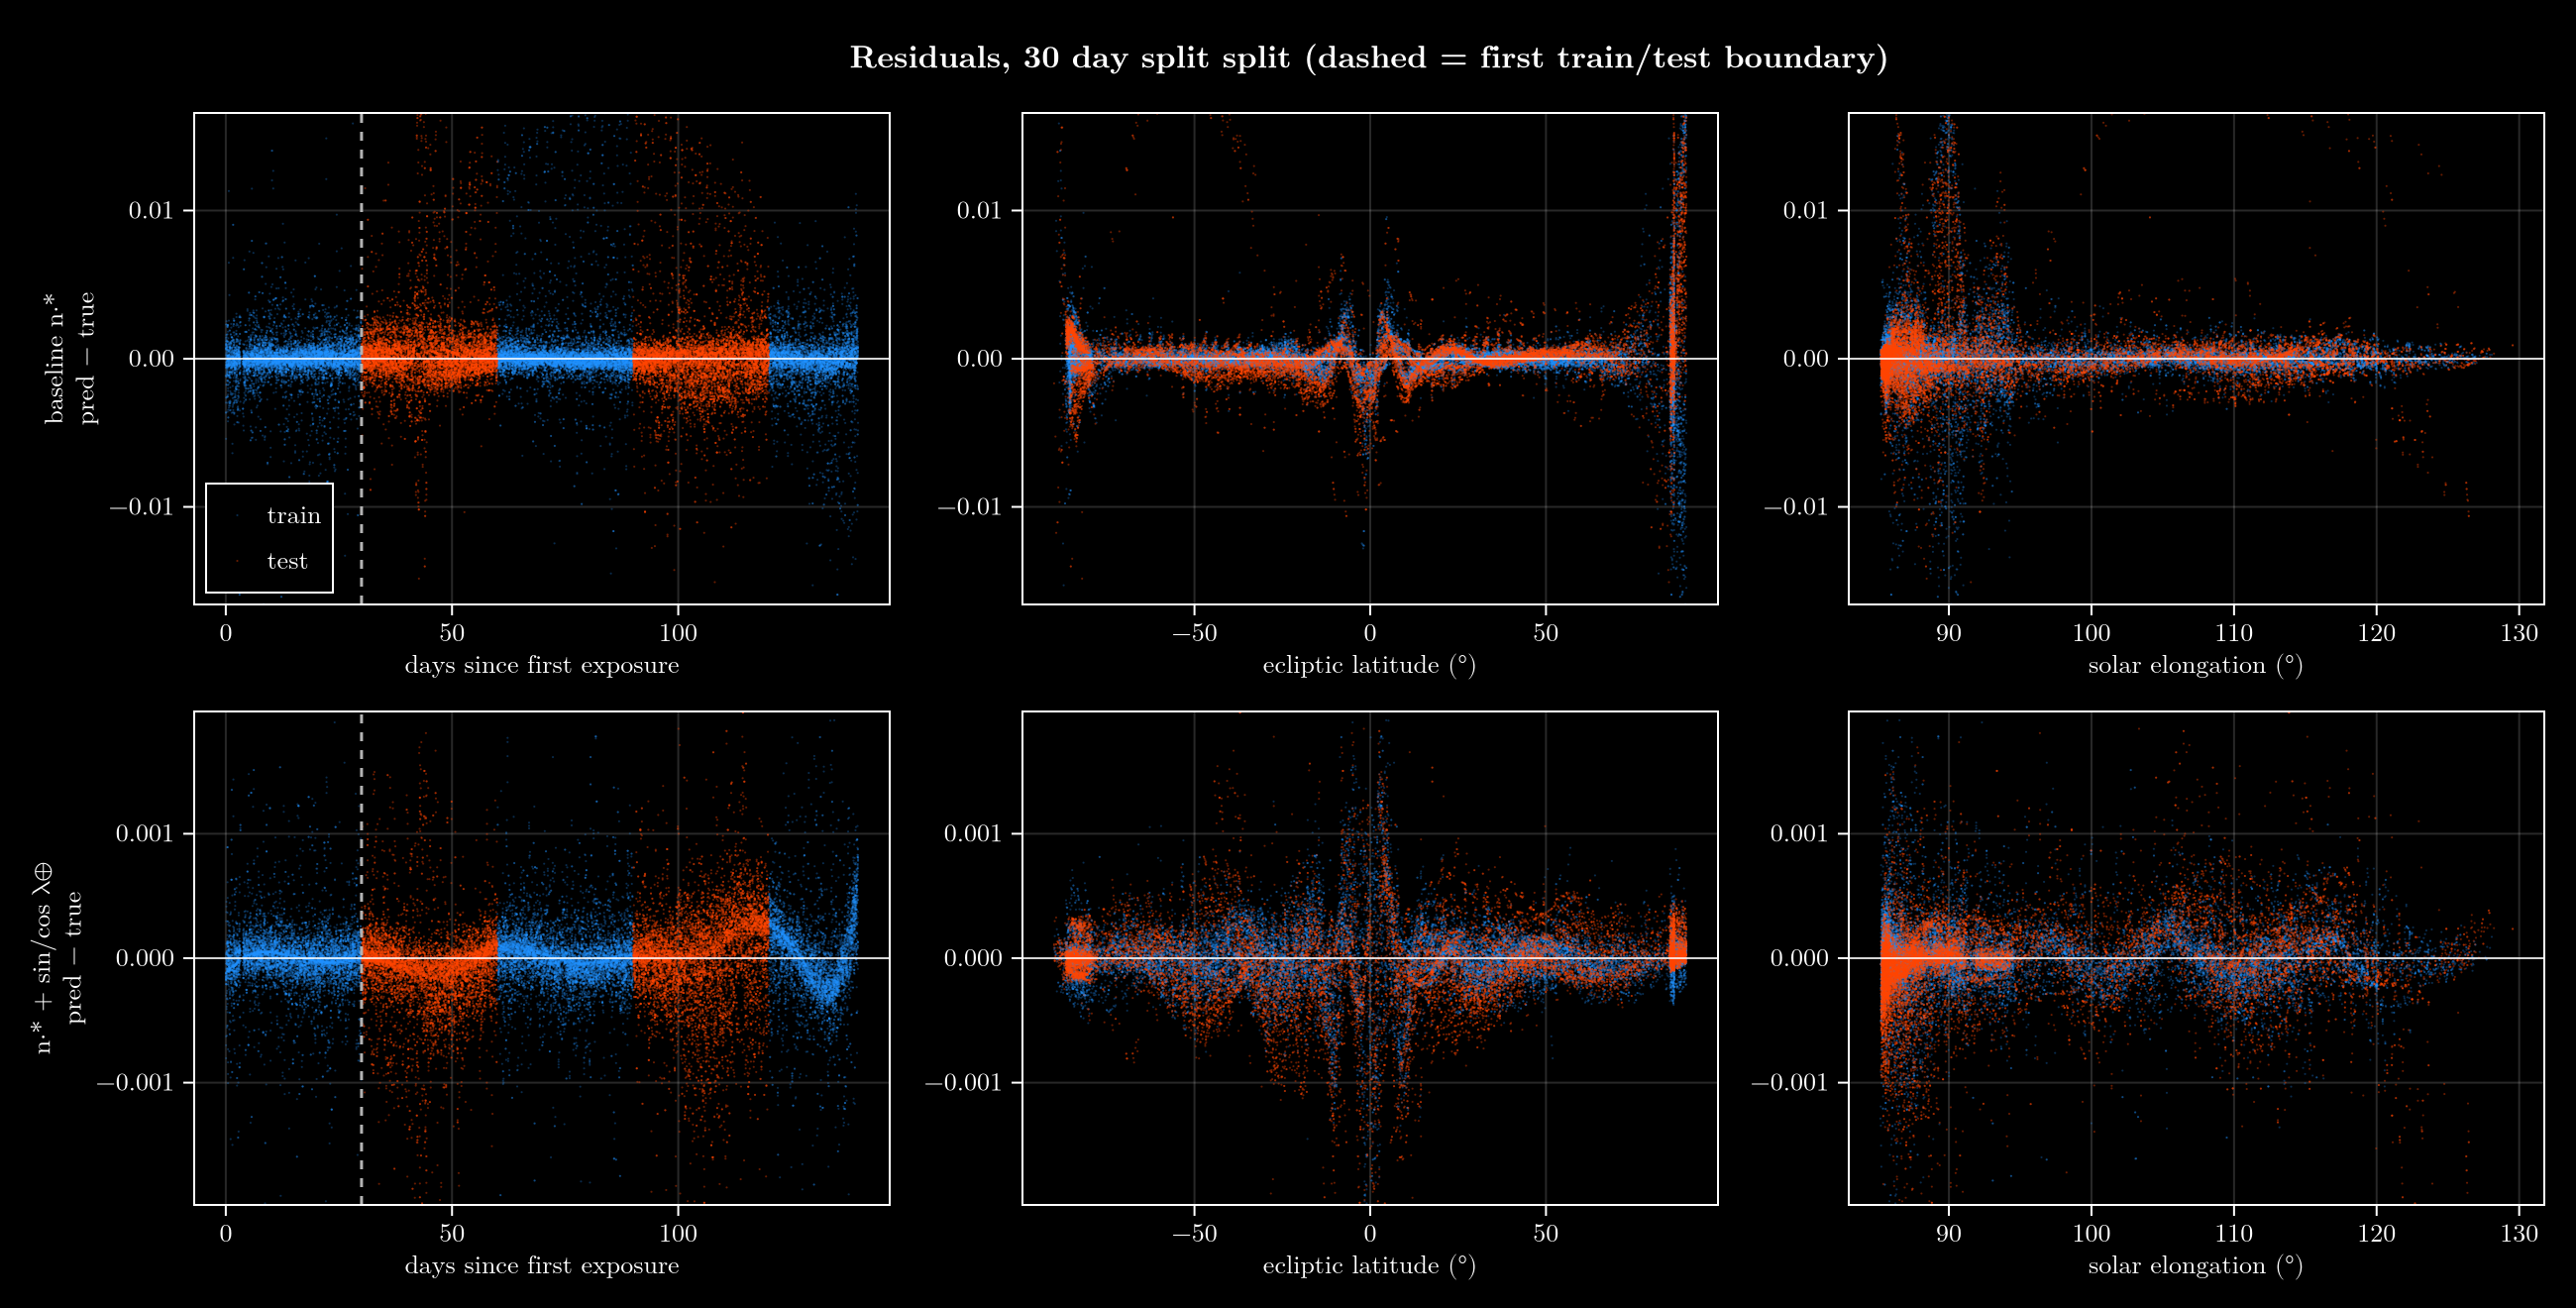

In [8]:
D_s = Dict{String, Any}(lbl => as_ensemble(grp_runs(spec), lbl) for (lbl, spec) in S_BLOCK)
verify_residuals(D_s, first.(S_BLOCK); tag="_season")


## #3 Log target revisited

### 3a. Ten seeds, paired by initialization


In [9]:
P = paired_seeds()
display(P.df)
@printf("log target beats linear in %d of %d paired seeds; geometric-mean MSE ratio (log/linear) = %.2f\n", P.log_wins, P.n, P.geo_mean_ratio)


Row,seed,linear,log_target,ratio_log_over_lin
,Int64,String,String,Float64
1,42,1.57e-04,3.24e-04,2.06
2,43,1.05e-04,1.30e-03,12.38
3,44,2.16e-04,8.38e-04,3.89
4,45,8.55e-05,2.19e-04,2.56
5,46,1.49e-04,1.47e-04,0.99
6,47,1.67e-04,1.70e-04,1.01
7,48,2.07e-04,1.24e-03,6.0
8,49,1.28e-04,3.75e-04,2.92
9,50,1.71e-04,1.39e-04,0.81


log target beats linear in 2 of 10 paired seeds; geometric-mean MSE ratio (log/linear) = 2.36


### 3b. All output choices — chronological and interpolation


In [10]:
println("chronological 80/20 (fit days 0–111.4):"); display(target_compare(T_CHRONO))
println("30-day blocks:"); display(target_compare(T_BLOCK))


Row,output,seeds,test_seed_median,test_seed_IQR,test_seed_max,test_ens,ens_median_frac_pct,ens_p95_frac_pct,late_bias
,String,Int64,String,String,String,String,Float64,Float64,String
1,linear (10 seeds),10,1.62e-04,1.34e-04 – 1.98e-04,2.47e-04,1.01e-04,0.486,5.05,-0.0061
2,log target (10 seeds),10,3.45e-04,1.82e-04 – 7.22e-04,1.30e-03,1.67e-04,0.653,4.69,-0.0080
3,mixed α=0.25 (5 seeds),5,2.47e-04,2.08e-04 – 3.00e-04,3.55e-04,1.42e-04,0.607,5.07,-0.0068
4,mixed α=1 (5 seeds),5,2.76e-04,2.47e-04 – 3.78e-04,9.58e-04,1.23e-04,0.746,4.4,-0.0026


chronological 80/20 (fit days 0–111.4):
30-day blocks:


Row,output,seeds,test_seed_median,test_seed_IQR,test_seed_max,test_ens,ens_median_frac_pct,ens_p95_frac_pct,late_bias
,String,Int64,String,String,String,String,Float64,Float64,String
1,linear,5,1.27e-05,1.24e-05 – 1.36e-05,1.57e-05,8.82e-06,0.142,1.46,—
2,log target,5,1.09e-05,1.06e-05 – 1.21e-05,4.13e-05,7.65e-06,0.149,1.1,—
3,mixed α=0.25,3,1.16e-05,1.10e-05 – 3.67e-05,6.18e-05,1.21e-05,0.187,1.27,—
4,mixed α=1,3,1.20e-05,1.12e-05 – 7.07e-05,1.30e-04,2.07e-05,0.169,1.27,—


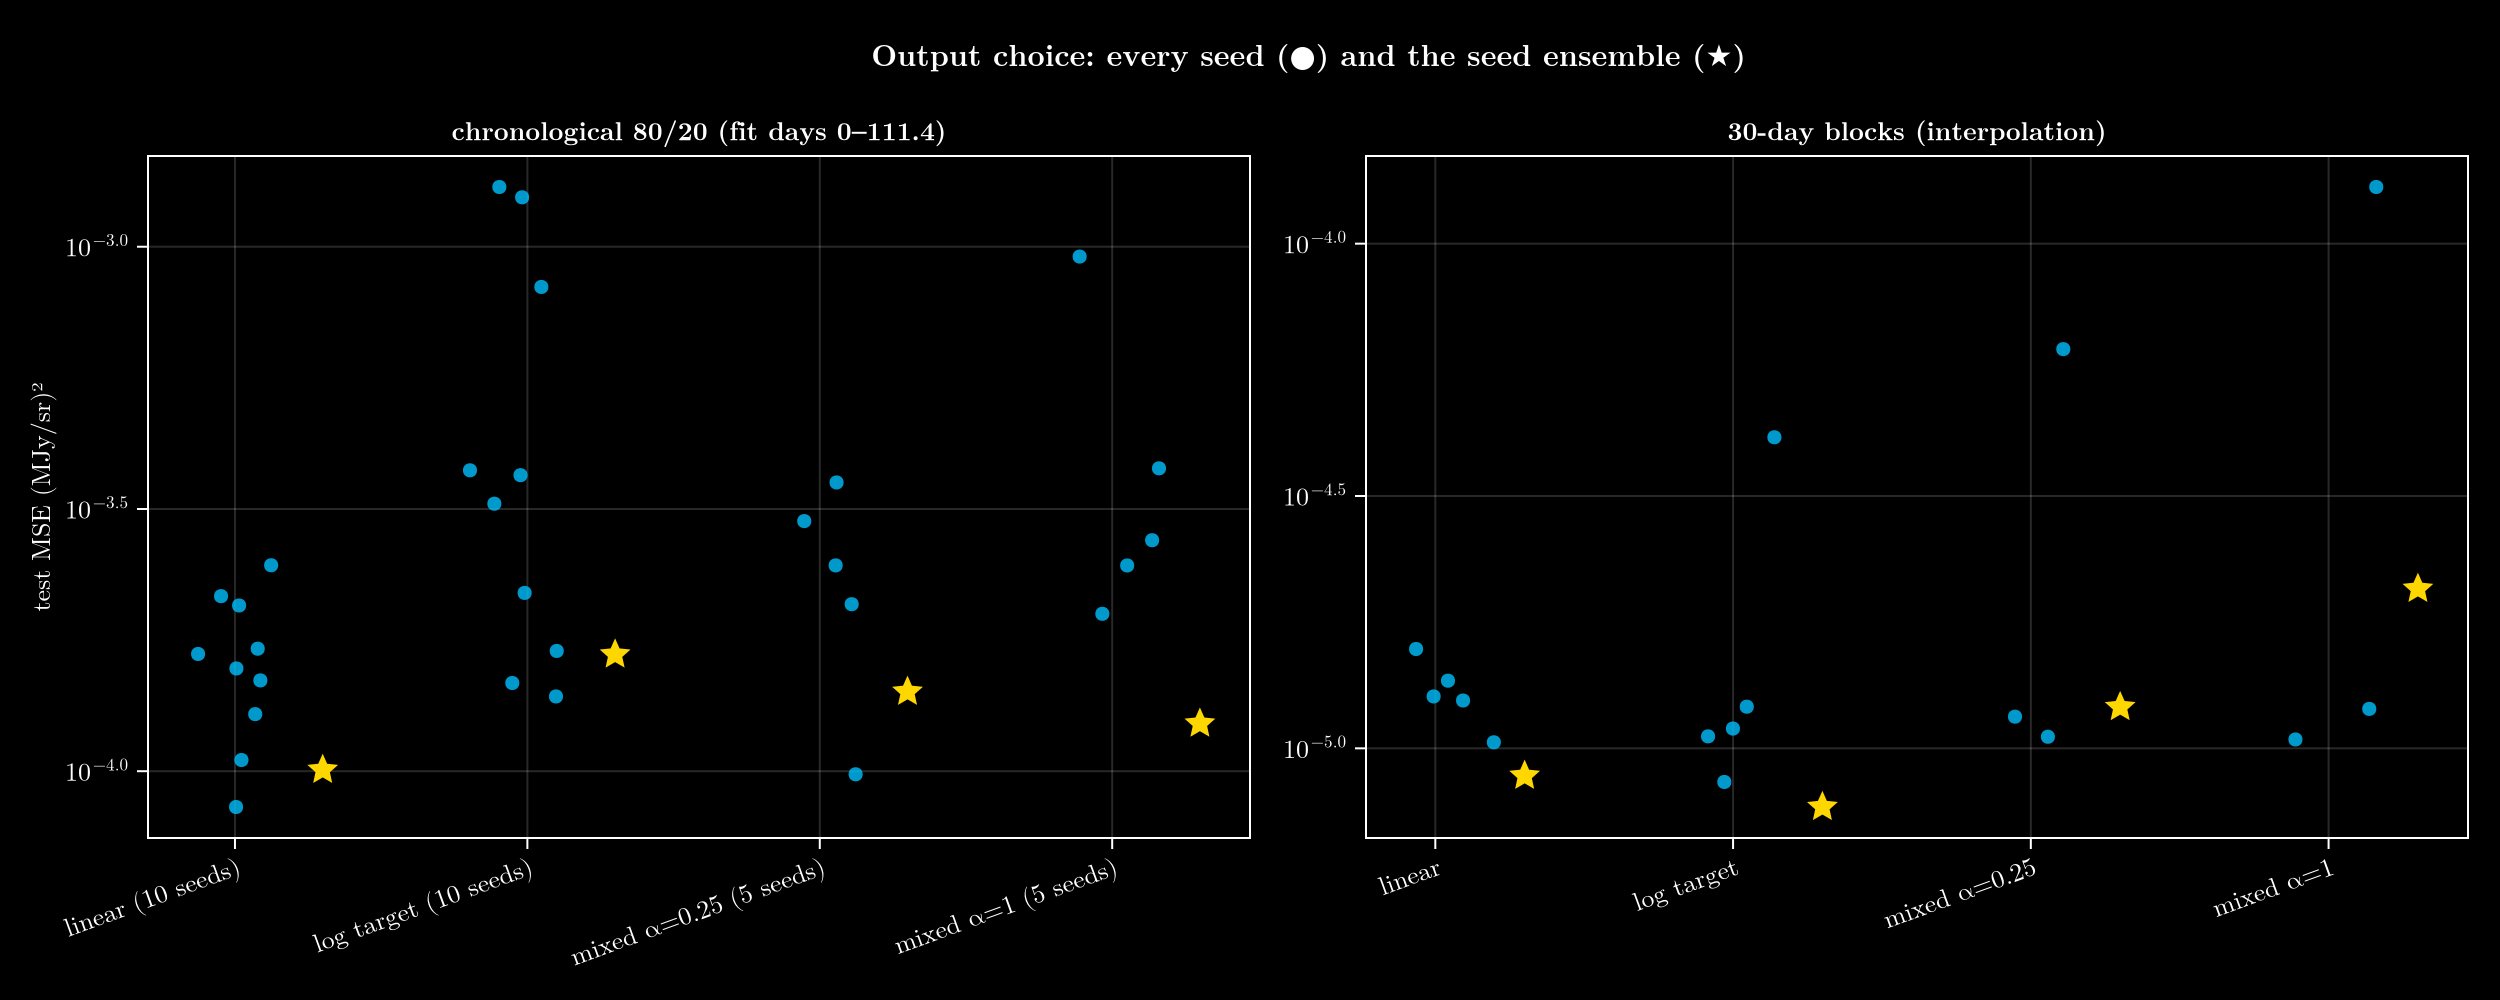

In [11]:
seed_strip_fig(T_CHRONO, T_BLOCK)


### 3c. All-sky behaviour (chronological-fit ensembles)


In [12]:
rows = map(T_CHRONO) do (lbl, spec)
    A = allsky_eval(trun(spec); title=lbl); sun = A.elong .< 60
    (; output=lbl, in_domain_rms=round(A.metrics.rms_MJy_sr[1], digits=4), in_domain_median_err_pct=round(A.metrics.median_abs_frac_pct[1], digits=3),
       out_domain_median_err_pct=round(A.metrics.median_abs_frac_pct[2], digits=2), near_sun_median_err_pct=round(100median(abs.(A.res[sun]) ./ A.yt[sun]), digits=1),
       negative_predictions=A.metrics.negative_predictions[3])
end
DataFrame(rows)


Row,output,in_domain_rms,in_domain_median_err_pct,out_domain_median_err_pct,near_sun_median_err_pct,negative_predictions
,String,Float64,Float64,Float64,Float64,Int64
1,linear (10 seeds),0.0075,0.587,5.95,44.1,0
2,log target (10 seeds),0.0092,0.315,7.52,65.6,0
3,mixed α=0.25 (5 seeds),0.0073,0.506,13.35,1147.7,0
4,mixed α=1 (5 seeds),0.0072,0.473,10.1,76.7,0


## Conclusions

**#1 Season features — the missing variable found.**
* Physically, Kelsall's brightness along a line of sight depends on *where the observer is* in the (tilted, offset) dust
  cloud. The `n·*` features only described the look direction relative to moving vectors; they never told the network
  where Earth is in its orbit. `sin/cos λ⊕` supplies exactly that information (the same as `S·x`, `S·y`), in a periodic
  form that interpolates cleanly over a full year.
* On interpolation splits error drops 44–65× (median 0.03%), and each symptom traced to this blind spot disappears:
  pole scatter (rms 2.5–4.4% → 0.03–0.04%), the weak north/south asymmetry (amplitude 73% → 98%, pattern corr 0.998),
  and the inability to follow the seasonal pole brightness (see the pole time series).
* It is not leakage: partitions are clean, normalization uses training rows only, block-split test exposures are a median
  7.4 days (up to 15) from any training exposure yet gain as much as the random split, and the features contain only
  Earth's position.
* Even when extrapolating (chronological), season features help 7× on the test period — they are smooth and only slightly
  out of range — but the honest regime for them is a full year of data, where they are always in range.
* **What's left:** residuals now concentrate within ±10° of the ecliptic, where Kelsall's narrow asteroid dust bands
  live — the component the onboarding predicted would be hardest — plus a smooth wiggle near the end of the covered orbit.

**#3 Log target — linear output stays.**
* With 10 paired seeds the log target loses on the chronological test (2/10 wins; 2.4× median MSE) and has the widest
  seed spread; the mixed loss sits between the two.
* It does reach the best all-sky in-domain fractional error (0.32% vs 0.59%), and slightly better tails (95th percentile).
* Physically important caveat: an exponential output **extrapolates multiplicatively** — toward the Sun the mixed-loss
  model's median error is ~1100% (log target 66%, linear 44%). For an emulator that may be queried out of domain, the
  linear output is safer.
* No variant ever predicts a negative value.

**Recommendations**
1. **Adopt `sin/cos λ⊕` in the recommended model** (`FEATURE_SETS[:look_dir_season]`), and plan on training data that
   covers the full year so the season is always interpolated.
2. Keep linear output + MSE; revisit the log target only together with season features (its in-domain fractional
   advantage may persist without the seed sensitivity — untested).
3. Next physics target: the ecliptic dust bands (features sharp in latitude, e.g. ecliptic latitude of the line of sight
   relative to the band planes), now visible as the dominant residual.
4. A v2 packaged emulator with season features would need Earth's longitude as an input (one line in `ZodiEmulator`).
